In [36]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "datasets" / "processed"
FIGURES = ROOT / "figures"

DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SAMPLE_FILE = DATA / "agreement_analysis_sample.csv"

if not SAMPLE_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find Task 9 sample: {SAMPLE_FILE}"
    )

df = pd.read_csv(
    SAMPLE_FILE,
    dtype={"soc2018": "string"}
)

print("Project root:", ROOT)
print("Dataset shape:", df.shape)
print("Unique SOC codes:", df["soc2018"].nunique())


Project root: C:\Users\Staneisha\Desktop\Swytch-1A-do-ai-job-risk-indices-agree
Dataset shape: (663, 225)
Unique SOC codes: 663


In [37]:

RANK_COLUMNS = [
    "rank_aioe",
    "rank_fo",
    "rank_elo_dv",
    "rank_elo_hum"
]

required = ["soc2018", "title"] + RANK_COLUMNS

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

assert len(df) == 663, "Expected 663 occupations"
assert df["soc2018"].is_unique, "Duplicate SOC codes found"
assert df[RANK_COLUMNS].notna().all().all(), "Missing ranks found"

for col in RANK_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="raise")

assert np.isfinite(df[RANK_COLUMNS].to_numpy()).all()
assert df[RANK_COLUMNS].ge(0).all().all()
assert df[RANK_COLUMNS].le(1).all().all()

scaler = StandardScaler()
X = scaler.fit_transform(df[RANK_COLUMNS])

print("Standardized feature means:")
print(np.round(X.mean(axis=0), 4))

print("\nStandardized feature standard deviations:")
print(np.round(X.std(axis=0), 4))


Standardized feature means:
[-0. -0. -0. -0.]

Standardized feature standard deviations:
[1. 1. 1. 1.]


In [38]:

def assign_tier(score):
    if score <= 0.25:
        return "Low"
    elif score <= 0.50:
        return "Medium"
    elif score <= 0.75:
        return "High"
    else:
        return "Very High"


df["consensus_rank_gpt4"] = df[
    ["rank_aioe", "rank_fo", "rank_elo_dv"]
].mean(axis=1)

df["consensus_rank_human"] = df[
    ["rank_aioe", "rank_fo", "rank_elo_hum"]
].mean(axis=1)

df["consensus_tier_gpt4"] = (
    df["consensus_rank_gpt4"].apply(assign_tier)
)

df["consensus_tier_human"] = (
    df["consensus_rank_human"].apply(assign_tier)
)

# Descriptive disagreement metric, not a confidence flag.
df["rank_spread_gpt4"] = (
    df[["rank_aioe", "rank_fo", "rank_elo_dv"]].max(axis=1)
    - df[["rank_aioe", "rank_fo", "rank_elo_dv"]].min(axis=1)
)

df["rank_spread_human"] = (
    df[["rank_aioe", "rank_fo", "rank_elo_hum"]].max(axis=1)
    - df[["rank_aioe", "rank_fo", "rank_elo_hum"]].min(axis=1)
)

print("GPT-4 consensus tier counts:")
print(df["consensus_tier_gpt4"].value_counts())

print("\nHuman consensus tier counts:")
print(df["consensus_tier_human"].value_counts())

print("\nAverage GPT-4 rank spread:",
      round(df["rank_spread_gpt4"].mean(), 4))


GPT-4 consensus tier counts:
consensus_tier_gpt4
Medium       315
High         244
Very High     64
Low           40
Name: count, dtype: int64

Human consensus tier counts:
consensus_tier_human
Medium       320
High         241
Very High     64
Low           38
Name: count, dtype: int64

Average GPT-4 rank spread: 0.4667


C:\Users\Staneisha\AppData\Local\Temp\ipykernel_39716\1434808660.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["consensus_rank_gpt4"] = df[
C:\Users\Staneisha\AppData\Local\Temp\ipykernel_39716\1434808660.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["consensus_rank_human"] = df[
C:\Users\Staneisha\AppData\Local\Temp\ipykernel_39716\1434808660.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joini

In [39]:

results = []
models = {}

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    results.append({
        "k": k,
        "silhouette_score": score,
        "inertia": model.inertia_,
        "smallest_cluster": int(
            pd.Series(labels).value_counts().min()
        )
    })

    models[k] = model

evaluation = pd.DataFrame(results)

print("K-Means evaluation:")
print(evaluation.to_string(index=False))

best_k = int(
    evaluation.loc[
        evaluation["silhouette_score"].idxmax(), "k"
    ]
)

print("\nBest silhouette-score solution:", best_k)


K-Means evaluation:
 k  silhouette_score     inertia  smallest_cluster
 2          0.478847 1125.565968               331
 3          0.447573  822.102776                96
 4          0.390946  630.115182                93
 5          0.354469  503.860630                77

Best silhouette-score solution: 2


In [40]:

df["cluster"] = models[best_k].labels_

# Cluster labels are arbitrary identifiers, not rankings.
profile_columns = (
    RANK_COLUMNS
    + ["rank_spread_gpt4", "rank_spread_human"]
)

profiles = (
    df.groupby("cluster")[profile_columns]
    .mean()
    .round(4)
)

profiles.insert(
    0,
    "occupation_count",
    df.groupby("cluster").size()
)

print("Cluster profiles:")
print(profiles.to_string())

print("\nClusters versus GPT-4 consensus tiers:")
tier_order = ["Low", "Medium", "High", "Very High"]

cluster_tier_counts = pd.crosstab(
    df["cluster"],
    df["consensus_tier_gpt4"]
).reindex(columns=tier_order, fill_value=0)

print(cluster_tier_counts)

print("\nWithin-cluster tier proportions:")
cluster_tier_pct = (
    cluster_tier_counts.div(
        cluster_tier_counts.sum(axis=1), axis=0
    ) * 100
).round(1)

print(cluster_tier_pct)


Cluster profiles:
         occupation_count  rank_aioe  rank_fo  rank_elo_dv  rank_elo_hum  rank_spread_gpt4  rank_spread_human
cluster                                                                                                      
0                     332     0.7421   0.3612       0.7368        0.7412            0.4750             0.4784
1                     331     0.2587   0.6407       0.2640        0.2596            0.4584             0.4636

Clusters versus GPT-4 consensus tiers:
consensus_tier_gpt4  Low  Medium  High  Very High
cluster                                          
0                      0      80   188         64
1                     40     235    56          0

Within-cluster tier proportions:
consensus_tier_gpt4   Low  Medium  High  Very High
cluster                                           
0                     0.0    24.1  56.6       19.3
1                    12.1    71.0  16.9        0.0


C:\Users\Staneisha\AppData\Local\Temp\ipykernel_39716\1331480574.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cluster"] = models[best_k].labels_


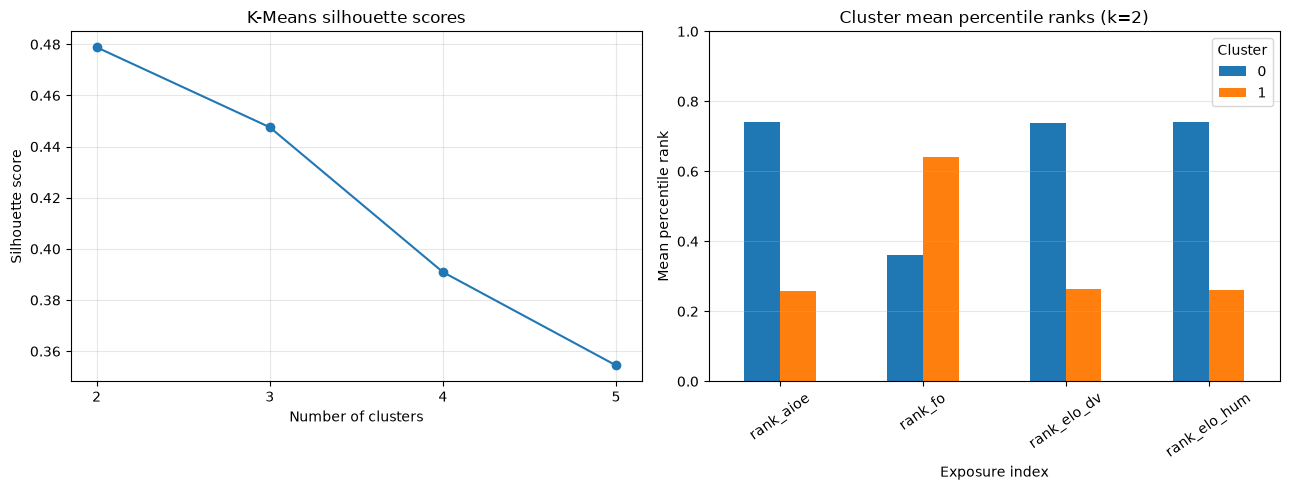

Saved: C:\Users\Staneisha\Desktop\Swytch-1A-do-ai-job-risk-indices-agree\figures\task16_cluster_comparison.png


In [41]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Silhouette scores by k
axes[0].plot(
    evaluation["k"],
    evaluation["silhouette_score"],
    marker="o"
)

axes[0].set_title("K-Means silhouette scores")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[0].set_xticks([2, 3, 4, 5])
axes[0].grid(alpha=0.3)

# Cluster profiles in original percentile-rank units
profiles[RANK_COLUMNS].T.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title(
    f"Cluster mean percentile ranks (k={best_k})"
)
axes[1].set_xlabel("Exposure index")
axes[1].set_ylabel("Mean percentile rank")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend(title="Cluster")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

CHART_FILE = FIGURES / "task16_cluster_comparison.png"
plt.savefig(CHART_FILE, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", CHART_FILE)


In [42]:

ASSIGNMENTS_FILE = DATA / "task16_cluster_assignments.csv"
PROFILES_FILE = DATA / "task16_cluster_profiles.csv"

assignment_columns = [
    "soc2018",
    "title",
    *RANK_COLUMNS,
    "consensus_rank_gpt4",
    "consensus_rank_human",
    "consensus_tier_gpt4",
    "consensus_tier_human",
    "rank_spread_gpt4",
    "rank_spread_human",
    "cluster"
]

df[assignment_columns].to_csv(
    ASSIGNMENTS_FILE,
    index=False
)

profiles.reset_index().to_csv(
    PROFILES_FILE,
    index=False
)

print("Saved:", ASSIGNMENTS_FILE)
print("Saved:", PROFILES_FILE)


Saved: C:\Users\Staneisha\Desktop\Swytch-1A-do-ai-job-risk-indices-agree\data\datasets\processed\task16_cluster_assignments.csv
Saved: C:\Users\Staneisha\Desktop\Swytch-1A-do-ai-job-risk-indices-agree\data\datasets\processed\task16_cluster_profiles.csv


### Task 16: Exploratory K-Means Clustering Summary -Neisha

K-Means clustering was performed on 663 occupations using four standardized percentile-rank features: AIOE, Frey-Osborne, Eloundou GPT-4 beta, and Eloundou human beta.

Solutions with two through five clusters were evaluated using silhouette scores. The two-cluster solution achieved the highest silhouette score (0.4788), producing two balanced groups containing 332 and 331 occupations.

**Cluster 0** exhibited relatively high AIOE, GPT-4 beta, and human beta percentile ranks, but lower Frey-Osborne rankings. **Cluster 1** exhibited the opposite pattern, with higher Frey-Osborne rankings and lower modern AI exposure rankings.

Comparing cluster assignments with consensus exposure tiers revealed that both clusters contained medium- and high-tier occupations. This suggests that clustering may provide additional information beyond consensus classifications by identifying different combinations of index rankings.

The average GPT-4 component rank spreads were similar across clusters (0.4750 and 0.4584), indicating that clustering primarily differentiated the direction of index disagreement rather than its overall magnitude.

**Conclusion:** The two-cluster solution provides a potentially useful descriptive distinction between modern AI exposure and traditional computerisation potential. We recommend retaining the exploratory clustering appendix, subject to further review of occupation-level examples and reproducibility checks.

These results describe relative occupational exposure patterns and should not be interpreted as predictions of job displacement or unemployment.